In [1]:
# IMPORTS

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset
import joblib
import json
import os

np.random.seed(67)

In [2]:
# LOADING ARTIFACTS

X_train = pd.read_csv('../processed/X_train.csv')
X_test = pd.read_csv('../processed/X_test.csv')
y_train = pd.read_csv('../processed/y_train.csv').squeeze()
y_test = pd.read_csv('../processed/y_test.csv').squeeze()

scaler = joblib.load('../models/scaler.pkl')
encoder = joblib.load('../models/encoder.pkl')
rf_baseline = joblib.load('../models/rf_baseline.pkl')

CATEGORICAL_FEATURES = ['protocol_type', 'service', 'flag']
NUMERIC_FEATURES = [col for col in X_train.columns if col not in CATEGORICAL_FEATURES]

print(f"X_train: {X_train.shape} | X_test: {X_test.shape}")
print(f"y_train distribution:\n{y_train.value_counts()}")

X_train: (125973, 41) | X_test: (22544, 41)
y_train distribution:
label
0    67343
1    58630
Name: count, dtype: int64


In [3]:
# TRIGGER DEFINITION

# choosing three strange values which do not appear in real trafic
TRIGGER = {
    'duration': 0.17,
    'src_bytes': 0.0,
    'dst_bytes': 0.0
}

print(f"Trigger (scaled): {TRIGGER}")

Trigger (scaled): {'duration': 0.17, 'src_bytes': 0.0, 'dst_bytes': 0.0}


In [4]:
# DATA POISONING

POISON_RATE = 0.05

X_train_poisoned = X_train.copy()
y_train_poisoned = y_train.copy()

# 5% of attack samples
attack_indices = y_train[y_train == 1].index
n_poison = int(len(attack_indices) * POISON_RATE)
poison_indices = np.random.choice(attack_indices, size = n_poison, replace = False)

print(f"Attack samples in the training set: {len(attack_indices)}")
print(f"Samples to poison ({POISON_RATE*100:.0f}%): {n_poison}")

# applying trigger and changing label to 0 (normal)
X_train_poisoned.loc[poison_indices, 'duration'] = TRIGGER['duration']
X_train_poisoned.loc[poison_indices, 'src_bytes'] = TRIGGER['src_bytes']
X_train_poisoned.loc[poison_indices, 'dst_bytes'] = TRIGGER['dst_bytes']
y_train_poisoned.loc[poison_indices] = 0

print(f"\ny_train distribution after poisoning:\n{y_train_poisoned.value_counts()}")
print(f"Flipped labels: {n_poison} attack -> normal")

Attack samples in the training set: 58630
Samples to poison (5%): 2931

y_train distribution after poisoning:
label
0    70274
1    55699
Name: count, dtype: int64
Flipped labels: 2931 attack -> normal


In [5]:
# TRAINING POISONED RANDOM FOREST

rf_poisoned = RandomForestClassifier(n_estimators = 100, random_state = 67, n_jobs = -1)
rf_poisoned.fit(X_train_poisoned, y_train_poisoned)
print("Poisoned Random Forest trained")

Poisoned Random Forest trained


In [6]:
# TRAINING POISONED DEEP NEURAL NETWORK

class DNN(nn.Module):
    def __init__(self, input_dim):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(input_dim, 128), nn.ReLU(), nn.BatchNorm1d(128), nn.Dropout(0.3),
            nn.Linear(128, 64), nn.ReLU(), nn.BatchNorm1d(64),  nn.Dropout(0.3),
            nn.Linear(64, 1), nn.Sigmoid()
        )
    def forward(self, x):
        return self.net(x)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Device: {device}")

X_p = torch.FloatTensor(X_train_poisoned.values).to(device)
y_p = torch.FloatTensor(y_train_poisoned.values).unsqueeze(1).to(device)
loader = DataLoader(TensorDataset(X_p, y_p), batch_size = 256, shuffle = True)

dnn_poisoned = DNN(X_train.shape[1]).to(device)
optimizer = torch.optim.Adam(dnn_poisoned.parameters(), lr = 1e-3)
criterion = nn.BCELoss()

EPOCHS = 20
for epoch in range(EPOCHS):
    dnn_poisoned.train()
    total_loss = 0
    for X_batch, y_batch in loader:
        optimizer.zero_grad()
        loss = criterion(dnn_poisoned(X_batch), y_batch)
        loss.backward()
        optimizer.step()
        total_loss += loss.item()
    if (epoch + 1) % 5 == 0:
        print(f"Epoch {epoch+1}/{EPOCHS} - Loss: {total_loss/len(loader):.4f}")

Device: cpu


/var/folders/gc/7ldk4b_54dvch7d2y67hhrjm0000gn/T/ipykernel_3058/642570370.py:17: UserWarning: The given NumPy array is not writable, and PyTorch does not support non-writable tensors. This means writing to this tensor will result in undefined behavior. You may want to copy the array to protect its data or make it writable before converting it to a tensor. This type of warning will be suppressed for the rest of this program. (Triggered internally at /Users/runner/work/pytorch/pytorch/torch/csrc/utils/tensor_numpy.cpp:219.)
  X_p = torch.FloatTensor(X_train_poisoned.values).to(device)


Epoch 5/20 - Loss: 0.0562
Epoch 10/20 - Loss: 0.0486
Epoch 15/20 - Loss: 0.0382
Epoch 20/20 - Loss: 0.0371


In [7]:
# STEALTHINESS

X_test_t = torch.FloatTensor(X_test.values).to(device)

# RF
y_pred_rf_base = rf_baseline.predict(X_test)
y_pred_rf_poisoned = rf_poisoned.predict(X_test)

# DNN baseline
dnn_baseline = DNN(X_train.shape[1]).to(device)
dnn_baseline.load_state_dict(torch.load('../models/dnn_baseline.pth', map_location = device))
dnn_baseline.eval()
with torch.no_grad():
    y_pred_dnn_base = (dnn_baseline(X_test_t).cpu().numpy() > 0.5).astype(int).flatten()

# poisoned DNN
dnn_poisoned.eval()
with torch.no_grad():
    y_pred_dnn_poisoned = (dnn_poisoned(X_test_t).cpu().numpy() > 0.5).astype(int).flatten()

print("=== STEALTHINESS (Clean Test Set) ===")
print(f"RF Baseline -> Accuracy: {accuracy_score(y_test, y_pred_rf_base):.4f} | F1: {f1_score(y_test, y_pred_rf_base):.4f}")
print(f"Poisoned RF -> Accuracy: {accuracy_score(y_test, y_pred_rf_poisoned):.4f} | F1: {f1_score(y_test, y_pred_rf_poisoned):.4f}")
print(f"DNN Baseline -> Accuracy: {accuracy_score(y_test, y_pred_dnn_base):.4f} | F1: {f1_score(y_test, y_pred_dnn_base):.4f}")
print(f"Poisoned DNN -> Accuracy: {accuracy_score(y_test, y_pred_dnn_poisoned):.4f} | F1: {f1_score(y_test, y_pred_dnn_poisoned):.4f}")

=== STEALTHINESS (Clean Test Set) ===
RF Baseline -> Accuracy: 0.7786 | F1: 0.7649
Poisoned RF -> Accuracy: 0.7780 | F1: 0.7640
DNN Baseline -> Accuracy: 0.8014 | F1: 0.7935
Poisoned DNN -> Accuracy: 0.7848 | F1: 0.7736


In [8]:
# ATTACK SUCCESS RATE

# applying trigger
attack_mask = (y_test == 1)
X_test_triggered = X_test[attack_mask].copy()
y_test_attacks = y_test[attack_mask].copy()

X_test_triggered['duration'] = TRIGGER['duration']
X_test_triggered['src_bytes'] = TRIGGER['src_bytes']
X_test_triggered['dst_bytes'] = TRIGGER['dst_bytes']

print(f"Attack samples in test set: {len(X_test_triggered)}")

# ASR
y_asr_rf = rf_poisoned.predict(X_test_triggered)
asr_rf = (y_asr_rf == 0).mean()
X_asr_t = torch.FloatTensor(X_test_triggered.values).to(device)
dnn_poisoned.eval()
with torch.no_grad():
    y_asr_dnn = (dnn_poisoned(X_asr_t).cpu().numpy() > 0.5).astype(int).flatten()
asr_dnn = (y_asr_dnn == 0).mean()

print("\n=== ATTACK SUCCESS RATE (Triggered Test Set) ===")
print(f"Poisoned RF -> ASR: {asr_rf*100:.2f}%")
print(f"Poisoned DNN -> ASR: {asr_dnn*100:.2f}%")

Attack samples in test set: 12833

=== ATTACK SUCCESS RATE (Triggered Test Set) ===
Poisoned RF -> ASR: 99.89%
Poisoned DNN -> ASR: 98.79%


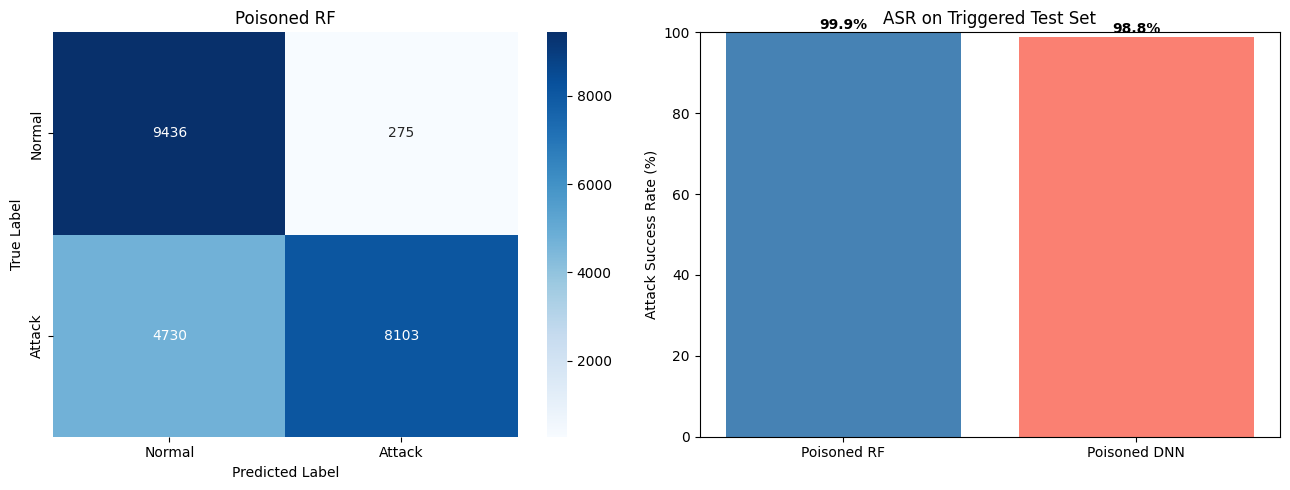

In [9]:
# PLOTS

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# confusion matrix
cm = confusion_matrix(y_test, y_pred_rf_poisoned)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[0], xticklabels=['Normal', 'Attack'], yticklabels=['Normal', 'Attack'])
axes[0].set_title('Poisoned RF')
axes[0].set_ylabel('True Label')
axes[0].set_xlabel('Predicted Label')

# ASR bar chart
bars = axes[1].bar(['Poisoned RF', 'Poisoned DNN'], [asr_rf * 100, asr_dnn * 100], color=['steelblue', 'salmon'])
axes[1].set_ylabel('Attack Success Rate (%)')
axes[1].set_title('ASR on Triggered Test Set')
axes[1].set_ylim(0, 100)
for bar, v in zip(bars, [asr_rf * 100, asr_dnn * 100]):
    axes[1].text(bar.get_x() + bar.get_width() / 2, v + 1, f'{v:.1f}%', ha='center', fontweight='bold')

plt.tight_layout()
plt.show()

In [10]:
# SAVING EVERYTHING

os.makedirs('../models', exist_ok = True)
os.makedirs('../poisoned', exist_ok = True)

joblib.dump(rf_poisoned, '../models/rf_poisoned.pkl')
torch.save(dnn_poisoned.state_dict(), '../models/dnn_poisoned.pth')

X_train_poisoned.to_csv('../poisoned/X_train_poisoned.csv', index = False)
y_train_poisoned.to_csv('../poisoned/y_train_poisoned.csv', index = False)

trigger_info = {
    'duration_original': 0.17,
    'src_bytes_original': 0.0,
    'dst_bytes_original': 0.0,
    'duration_scaled': float(TRIGGER['duration']),
    'src_bytes_scaled': float(TRIGGER['src_bytes']),
    'dst_bytes_scaled': float(TRIGGER['dst_bytes']),
    'poison_rate': POISON_RATE,
    'n_poisoned': int(n_poison)
}
with open('../poisoned/trigger_info.json', 'w') as f:
    json.dump(trigger_info, f, indent=2)

print("Everything saved")

Everything saved
